In [1]:
import pandas as pd
df=pd.read_csv("Online_Retail.csv")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
print("Dataset shape:",df.shape)
print("Dataset type:",df.dtypes)
print("Dataset stastical details:",df.describe())
print("Dataset information:",df.info())

Dataset shape: (541909, 8)
Dataset type: InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object
Dataset stastical details:             Quantity      UnitPrice     CustomerID
count  541909.000000  541909.000000  406829.000000
mean        9.552250       4.611114   15287.690570
std       218.081158      96.759853    1713.600303
min    -80995.000000  -11062.060000   12346.000000
25%         1.000000       1.250000   13953.000000
50%         3.000000       2.080000   15152.000000
75%        10.000000       4.130000   16791.000000
max     80995.000000   38970.000000   18287.000000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  o

In [3]:
print(df.isnull().sum())
print(df.duplicated().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
5268


In [4]:
cancelled_orders=df[df["InvoiceNo"].astype(str).str.startswith("C")]
print("Cancelled Transactions rows:",len(cancelled_orders))

Cancelled Transactions rows: 9288


In [5]:
print("negative quantites:",(df["Quantity"]<0).sum())
print("zero quantites:",(df["Quantity"]==0).sum())
print("zero prices:",(df["UnitPrice"]==0).sum())
print("negative prices:",(df["UnitPrice"]<0).sum())

negative quantites: 10624
zero quantites: 0
zero prices: 2515
negative prices: 2


In [6]:
df_copy=df.copy()
print("original dataset:",df.shape)
print("copied dataset:",df_copy.shape)

original dataset: (541909, 8)
copied dataset: (541909, 8)


In [7]:
df_clean=df_copy.drop_duplicates()
print("Rows after removing the duplicates:",df_clean.shape[0])
print("Remaining duplicate rows:",df_clean.duplicated().sum())

Rows after removing the duplicates: 536641
Remaining duplicate rows: 0


In [8]:
sales_df=df_clean[df_clean["InvoiceNo"].astype(str).str.startswith("C")].copy()
print("Rows before filtering:",df_clean.shape[0])
print("Rows after filtering:",sales_df.shape[0])
print("cancelled transactions remaining:",sales_df["InvoiceNo"].astype(str).str.startswith("C").sum())

Rows before filtering: 536641
Rows after filtering: 9251
cancelled transactions remaining: 9251


In [9]:
sales_df = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print("Rows before filtering:", len(df_clean))
print("Rows after filtering:", len(sales_df))

print(
    "Cancelled transactions remaining:",
    sales_df["InvoiceNo"].astype(str).str.startswith("C").sum()
)

Rows before filtering: 536641
Rows after filtering: 527390
Cancelled transactions remaining: 0


In [10]:
print("negative quantities:",(sales_df["Quantity"]<0).sum())
print("zero quantites:",(sales_df["Quantity"]==0).sum())
print("zero prices:",(sales_df["UnitPrice"]==0).sum())
print("negative prices:",(sales_df["UnitPrice"]<0).sum())

negative quantities: 1336
zero quantites: 0
zero prices: 2510
negative prices: 2


In [11]:
revenue_df=sales_df[(sales_df["Quantity"]>0)&(sales_df["UnitPrice"]>0)].copy()
revenue_df["Revenue"]=(revenue_df["Quantity"]*revenue_df["UnitPrice"])
print("Rows in sales data:",len(sales_df))
print("Rows for revenue analysis:",len(revenue_df))
print("total revenue:",revenue_df["Revenue"].sum())


Rows in sales data: 527390
Rows for revenue analysis: 524878
total revenue: 10642110.804000001


In [12]:
top_products=(revenue_df.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10))
print(top_products)


Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


Text(0.5, 1.0, 'top 10 items by thier revenue')

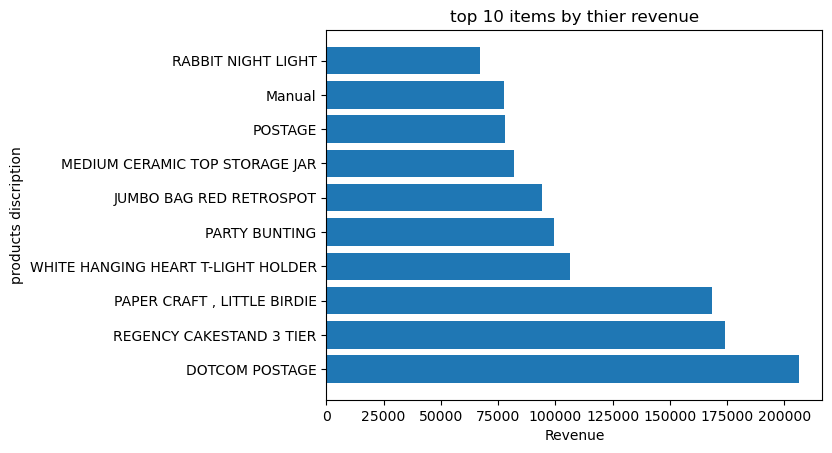

In [13]:
import matplotlib.pyplot as plt
plt.barh(top_products.index,top_products.values)
plt.xlabel("Revenue")
plt.ylabel("products discription")
plt.title("top 10 items by thier revenue")

In [14]:
top_countries=revenue_df.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10)
print(top_countries)

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


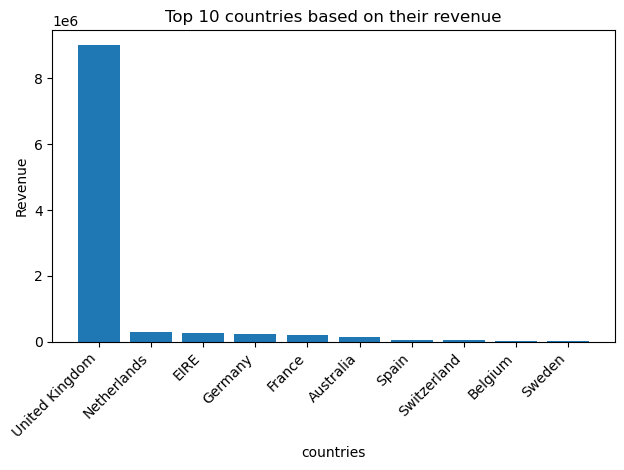

In [15]:
plt.bar(top_countries.index,top_countries.values)
plt.title("Top 10 countries based on their revenue")
plt.xlabel("countries")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [16]:
revenue_df["InvoiceDate"]=pd.to_datetime(revenue_df["InvoiceDate"])
revenue_df["Month"]=(revenue_df["InvoiceDate"].dt.to_period("M"))
monthly_revenue=revenue_df.groupby("Month")["Revenue"].sum().sort_index()
print(monthly_revenue)

Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64


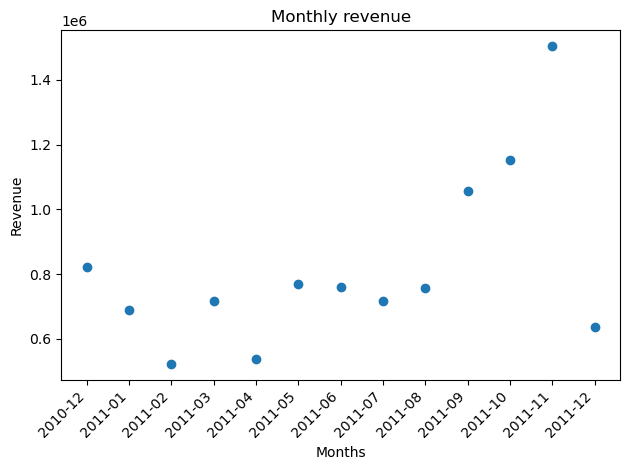

In [17]:
plt.plot(monthly_revenue.index.astype(str),monthly_revenue.values,"o")
plt.title("Monthly revenue")
plt.xlabel("Months")
plt.ylabel("Revenue")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

In [18]:
monthly_orders=(revenue_df.groupby("Month")["InvoiceNo"].nunique().sort_index())
print(monthly_orders)

Month
2010-12    1559
2011-01    1086
2011-02    1100
2011-03    1454
2011-04    1246
2011-05    1681
2011-06    1533
2011-07    1475
2011-08    1361
2011-09    1837
2011-10    2040
2011-11    2769
2011-12     819
Freq: M, Name: InvoiceNo, dtype: int64


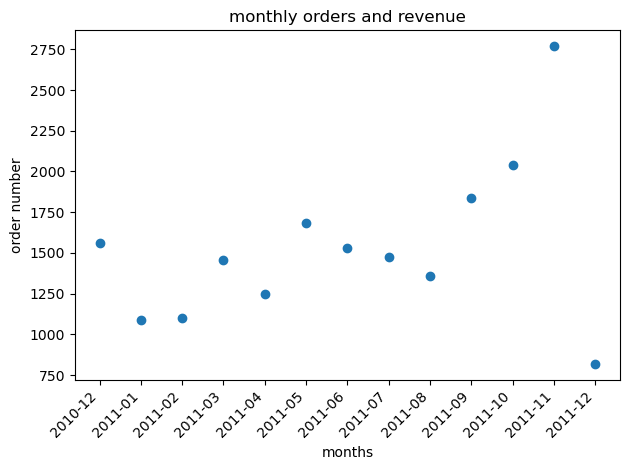

In [19]:
plt.plot(monthly_orders.index.astype(str),monthly_orders.values,"o")
plt.title("monthly orders and revenue")
plt.xlabel("months")
plt.ylabel("order number")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

In [20]:
top_customers=(revenue_df.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False).head(10))
print(top_customers)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64


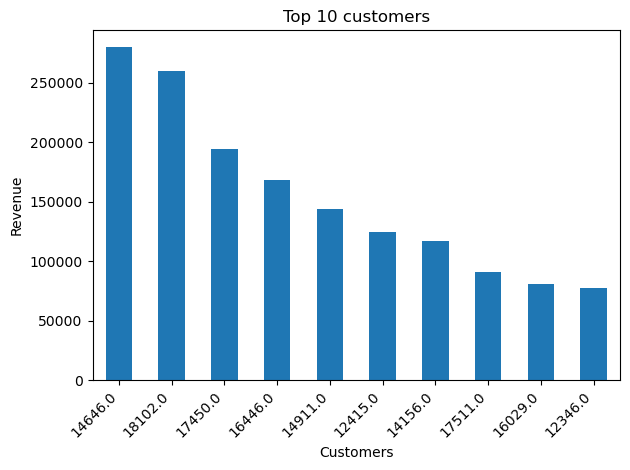

In [21]:
top_customers.plot(kind="bar")
plt.title("Top 10 customers")
plt.xlabel("Customers")
plt.ylabel("Revenue")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

In [22]:
revenue_df["InvoiceDate"]=pd.to_datetime(revenue_df["InvoiceDate"])
revenue_df["DayOfWeek"]=(revenue_df["InvoiceDate"].dt.day_name())
print(revenue_df["DayOfWeek"].value_counts())

DayOfWeek
Thursday     100213
Tuesday       98726
Monday        92466
Wednesday     91467
Friday        79667
Sunday        62339
Name: count, dtype: int64


In [23]:
daily_orders=revenue_df.groupby("DayOfWeek")["InvoiceNo"].nunique().reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"],fill_value=0)
print(daily_orders)

DayOfWeek
Monday       3126
Tuesday      3554
Wednesday    3690
Thursday     4246
Friday       3140
Saturday        0
Sunday       2204
Name: InvoiceNo, dtype: int64


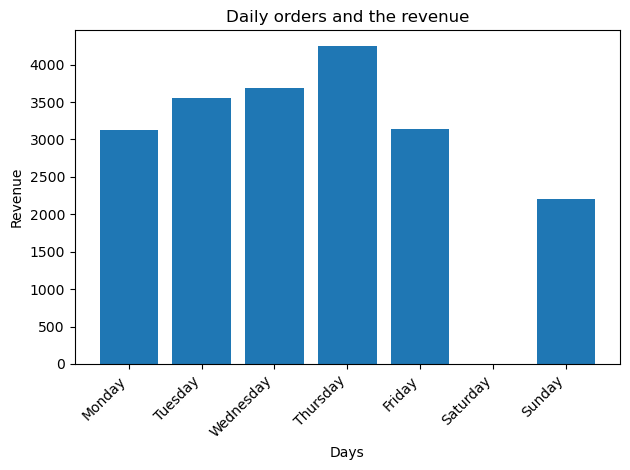

In [24]:
plt.bar(daily_orders.index,daily_orders.values)
plt.title("Daily orders and the revenue")
plt.xlabel("Days")
plt.ylabel("Revenue")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()


In [25]:
order_revenue=revenue_df.groupby("InvoiceNo")["Revenue"].sum()
average_order=order_revenue.mean()
print("average_order value :",average_order.round(2))

average_order value : 533.17


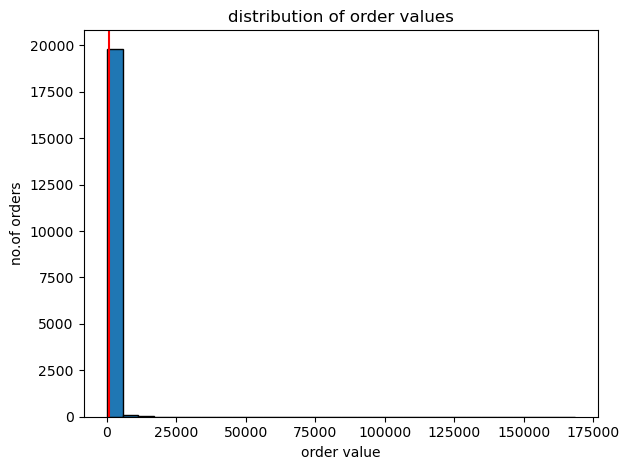

In [26]:
plt.hist(order_revenue,bins=30,edgecolor="black")
plt.axvline(average_order,color="red",label=f"average:{average_order:.2f}")
plt.title("distribution of order values")
plt.xlabel("order value")
plt.ylabel("no.of orders")
plt.tight_layout()
plt.show()

In [27]:
top_quality_products=revenue_df.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)
print(top_quality_products)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


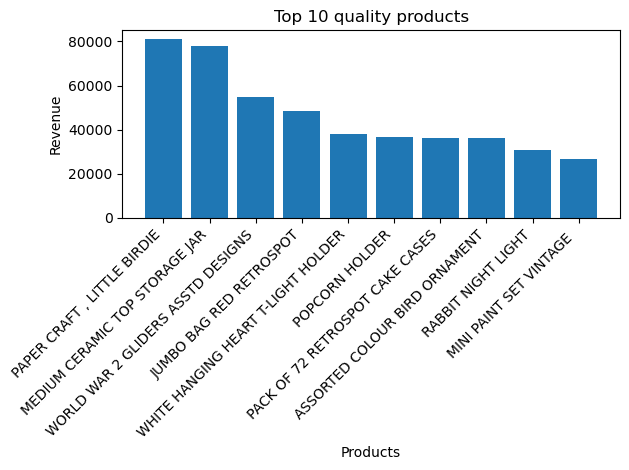

In [28]:
plt.bar(top_quality_products.index,top_quality_products.values)
plt.title("Top 10 quality products")
plt.xlabel("Products")
plt.ylabel("Revenue")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

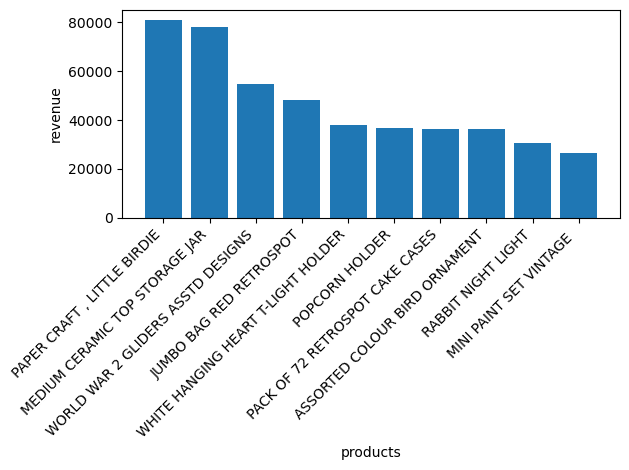

In [29]:
products=top_quality_products.sort_values(ascending=False)
plt.bar(products.index,products.values)
plt.xlabel("products")
plt.ylabel("revenue")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

In [33]:
product_comparision=revenue_df.groupby("Description").agg(Total_Revenue=("Revenue","sum"),Total_Quantity=("Quantity","sum")).sort_values("Total_Revenue",ascending=False)
print(product_comparision.head(10))

                                    Total_Revenue  Total_Quantity
Description                                                      
DOTCOM POSTAGE                          206248.77             706
REGENCY CAKESTAND 3 TIER                174156.54           13851
PAPER CRAFT , LITTLE BIRDIE             168469.60           80995
WHITE HANGING HEART T-LIGHT HOLDER      106236.72           37872
PARTY BUNTING                            99445.23           18283
JUMBO BAG RED RETROSPOT                  94159.81           48371
MEDIUM CERAMIC TOP STORAGE JAR           81700.92           78033
POSTAGE                                  78101.88            3150
Manual                                   77752.82            6985
RABBIT NIGHT LIGHT                       66870.03           30739


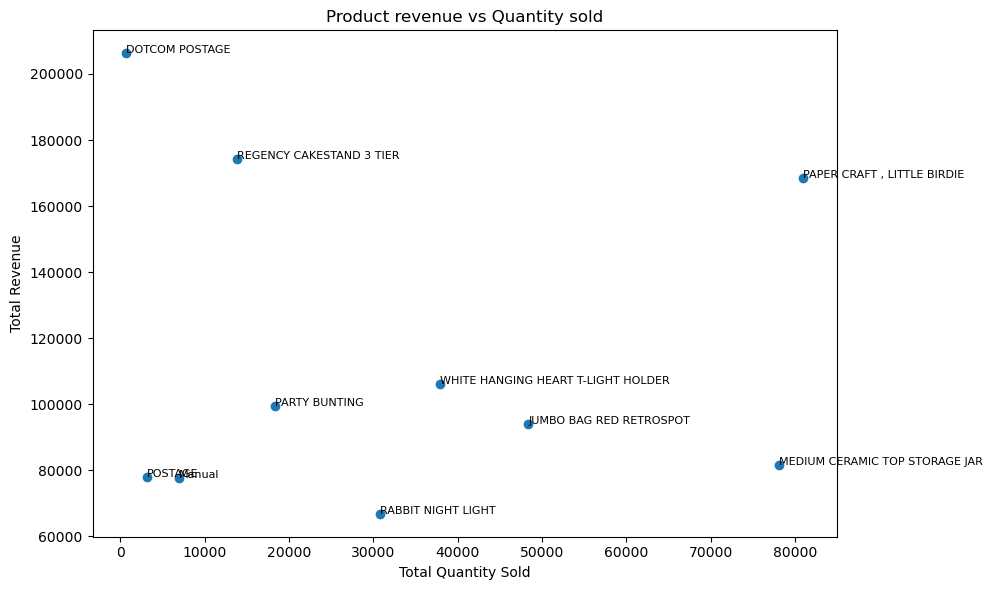

In [41]:
comparison_Top10=product_comparision.head(10)
plt.figure(figsize=(10,6))
plt.scatter(comparison_Top10["Total_Quantity"],comparison_Top10["Total_Revenue"])
for product,row in comparison_Top10.iterrows():
    plt.annotate(product,(row["Total_Quantity"],row["Total_Revenue"]),fontsize=8)
plt.title("Product revenue vs Quantity sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

In [44]:
customer_orders=revenue_df.groupby("CustomerID")["InvoiceNo"].nunique().sort_values(ascending=False)
print(customer_orders.head(10))

CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64


In [46]:
repeted_customers=customer_orders[customer_orders>1]
onetime_customers=customer_orders[customer_orders==1]
print("Total_Customers:",len(customer_orders))
print("Total Repeated_Customers:",len(repeted_customers))
print("Total onetime_customers:",len(onetime_customers))

Total_Customers: 4338
Total Repeated_Customers: 2845
Total onetime_customers: 1493


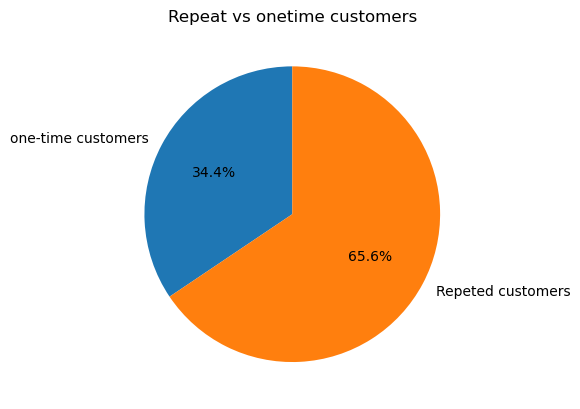

In [47]:
customer_types=[len(onetime_customers),len(repeted_customers)]
labels=["one-time customers","Repeted customers"]
plt.pie(customer_types,labels=labels,autopct="%1.1f%%",startangle=90)
plt.title("Repeat vs onetime customers")
plt.show()


Data Quality Validation

After completing the exploratory data analysis and visualizations, the dataset is validated to ensure that the results are reliable and meaningful.

The following checks will be performed:

Verify the dataset's date range.

Validate order distribution across weekdays.

Investigate unusual patterns in the data.

Review missing customer information and cleaning decisions.

Objective: Ensure the quality and reliability of the analysis before presenting the final business insights.

In [49]:
print("Start Date:",revenue_df["InvoiceDate"].min())
print("Ends Date:",revenue_df["InvoiceDate"].max())
print("\n orders by Day:")
print(revenue_df.groupby(revenue_df["InvoiceDate"].dt.day_name())["InvoiceNo"].nunique())


Start Date: 2010-12-01 08:26:00
Ends Date: 2011-12-09 12:50:00

 orders by Day:
InvoiceDate
Friday       3140
Monday       3126
Sunday       2204
Thursday     4246
Tuesday      3554
Wednesday    3690
Name: InvoiceNo, dtype: int64


nvestigating Saturday Order Activity

Saturday shows zero orders in the revenue analysis. To understand this result, weekday order counts are compared between the cleaned sales dataset and the filtered revenue dataset.

This helps determine whether Saturday records were absent from the original sales data or removed during the revenue filtering process.

In [51]:
sales_df["InvoiceDate"]=pd.to_datetime(sales_df["InvoiceDate"])
sales_df["DayOfWeek"]=sales_df["InvoiceDate"].dt.day_name()
sales_weekday_orders = (
  
    sales_df.groupby("DayOfWeek")["InvoiceNo"]
    .nunique()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ], fill_value=0)
)

print("Orders by Day in Cleaned Sales Data:")
print(sales_weekday_orders)

Orders by Day in Cleaned Sales Data:
DayOfWeek
Monday       3420
Tuesday      3973
Wednesday    4142
Thursday     4689
Friday       3633
Saturday        0
Sunday       2207
Name: InvoiceNo, dtype: int64


Weekday Order Validation – Key Findings

The weekday order comparison confirms that:

Thursday records the highest order volume in both datasets.

Saturday has zero recorded orders in both the cleaned sales dataset and filtered revenue dataset.

The absence of Saturday orders is not caused by the revenue filtering conditions.

The weekday order pattern remains consistent across both datasets.

Business Insight: Thursday appears to be the busiest recorded shopping day. The business could investigate customer purchasing patterns and promotional opportunities around this day.

Data Limitation: The dataset contains no Saturday transactions, so Saturday customer behavior cannot be evaluated from this data.


Missing Customer ID Analysis

Customer identification is important for customer-level analysis, including repeat purchase behavior and customer segmentation.

This section examines missing CustomerID values to understand how much customer information is unavailable in the dataset.

In [52]:
print("Total Rows:", len(revenue_df))

print(
    "Missing Customer IDs:",
    revenue_df["CustomerID"].isnull().sum()
)

print(
    "Missing Customer ID Percentage:",
    round(revenue_df["CustomerID"].isnull().mean() * 100, 2),
    "%"
)

Total Rows: 524878
Missing Customer IDs: 132186
Missing Customer ID Percentage: 25.18 %


Business Insights and Recommendations

This section interprets the results obtained from exploratory data analysis and translates them into meaningful business insights.

The objective is to identify sales patterns, understand customer purchasing behavior, evaluate product performance, and provide data-driven recommendations to support business decisions.

In [53]:
product_comparision["Revenue_Per_Unit"] = (
    product_comparision["Total_Revenue"] /
    product_comparision["Total_Quantity"]
)

product_comparision.sort_values(
    "Revenue_Per_Unit",
    ascending=False
).head(10)

,Total_Revenue,Total_Quantity,Revenue_Per_Unit
Description,,,
Adjust bad debt,11062.06,1,11062.060000
AMAZON FEE,13761.09,2,6880.545000
PICNIC BASKET WICKER 60 PIECES,39619.50,61,649.500000
DOTCOM POSTAGE,206248.77,706,292.137068
RUSTIC SEVENTEEN DRAWER SIDEBOARD,5415.00,35,154.714286
REGENCY MIRROR WITH SHUTTERS,1530.00,10,153.000000
VINTAGE BLUE KITCHEN CABINET,3685.00,26,141.730769
VINTAGE RED KITCHEN CABINET,8125.00,60,135.416667
CHEST NATURAL WOOD 20 DRAWERS,2745.00,24,114.375000


#Conclusion

The Customer Purchase Behavior Analysis project explored historical retail transaction data to understand sales performance, product trends, and customer purchasing patterns.

Using Python, Pandas, NumPy, Matplotlib, and Seaborn, the dataset was cleaned, analyzed, and visualized to identify meaningful patterns.

Key Findings

Identified the highest revenue-generating products and countries.

Analyzed monthly revenue and order trends to understand sales performance over time.

Identified top customers based on their purchase revenue.

Examined repeat and one-time customer purchasing behavior.

Compared product sales volume with revenue contribution.
 
Analyzed order distribution across different weekdays.

Learning Outcomes

This project provided practical experience in data cleaning, exploratory data analysis, data manipulation, statistical analysis, and visualization.

It also demonstrated how transaction data can be transformed into meaningful business insights to support data-driven decision-making.

In [57]:
# Calculate KPI values

total_revenue = revenue_df["Revenue"].sum()

total_orders = revenue_df["InvoiceNo"].nunique()

total_customers = revenue_df["CustomerID"].nunique()

repeat_percentage = (
    len(repeted_customers) / total_customers
) * 100

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Repeat Customers:", round(repeat_percentage, 2), "%")

Total Revenue: 10642110.8
Total Orders: 19960
Total Customers: 4338
Repeat Customers: 65.58 %


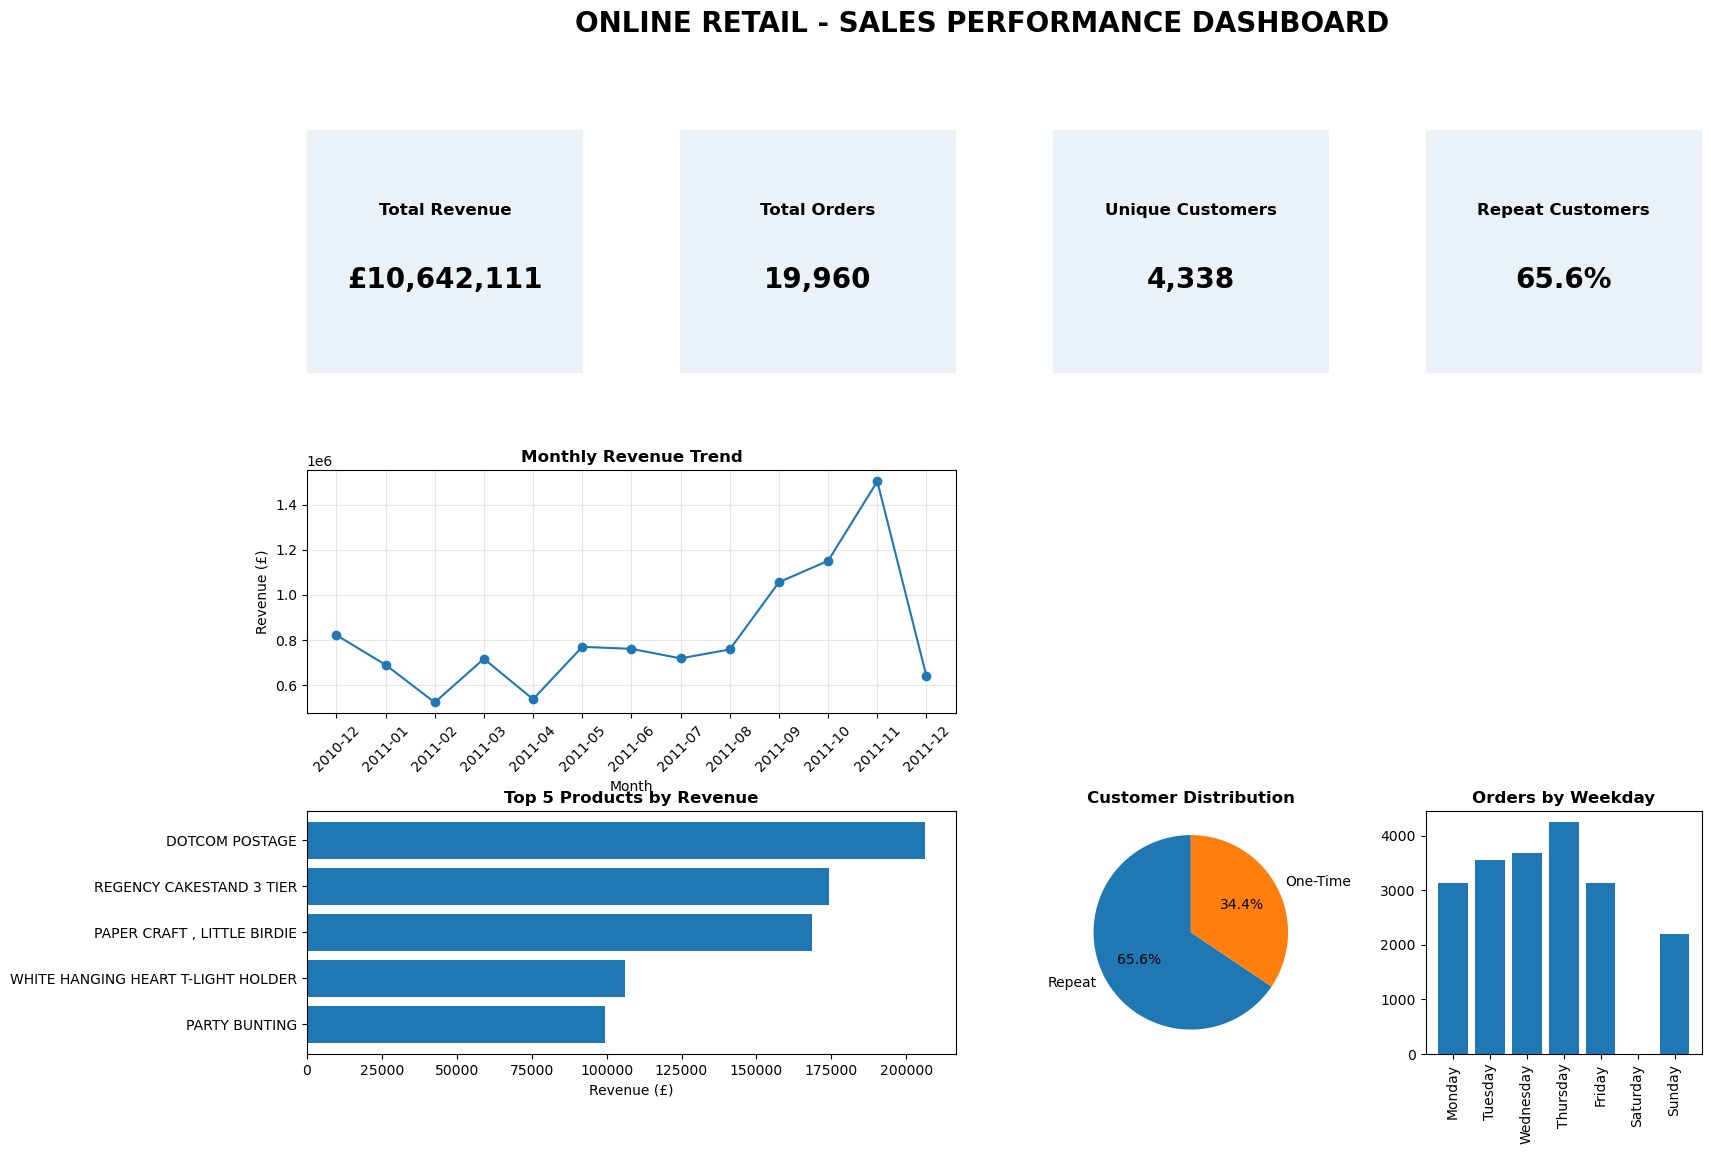

In [63]:
fig = plt.figure(figsize=(18, 12))

fig.suptitle(
    "ONLINE RETAIL - SALES PERFORMANCE DASHBOARD",
    fontsize=20,
    fontweight="bold"
)

# Create dashboard layout
gs = fig.add_gridspec(3, 4, hspace=0.4, wspace=0.35)

# KPI Cards
kpis = [
    ("Total Revenue", f"£{total_revenue:,.0f}"),
    ("Total Orders", f"{total_orders:,}"),
    ("Unique Customers", f"{total_customers:,}"),
    ("Repeat Customers", f"{repeat_percentage:.1f}%")
]

for i, (title, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])
    ax.set_facecolor("#EAF2F8")
    ax.text(0.5, 0.65, title, ha="center",
            fontsize=12, fontweight="bold")
    ax.text(0.5, 0.35, value, ha="center",
            fontsize=20, fontweight="bold")
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

# Monthly Revenue Trend
ax1 = fig.add_subplot(gs[1, :2])
ax1.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)
ax1.set_title("Monthly Revenue Trend", fontweight="bold")
ax1.set_xlabel("Month")
ax1.set_ylabel("Revenue (£)")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(alpha=0.3)



ax2.set_title("Top 5 Countries by Revenue", fontweight="bold")
ax2.set_xlabel("Revenue (£)")

# Top 5 Products
ax3 = fig.add_subplot(gs[2, :2])
ax3.barh(
    top_products.head(5).index[::-1],
    top_products.head(5).values[::-1]
)
ax3.set_title("Top 5 Products by Revenue", fontweight="bold")
ax3.set_xlabel("Revenue (£)")

# Repeat vs One-Time Customers
ax4 = fig.add_subplot(gs[2, 2])
ax4.pie(
    [len(repeted_customers), len(onetime_customers)],
    labels=["Repeat", "One-Time"],
    autopct="%1.1f%%",
    startangle=90
)
ax4.set_title("Customer Distribution", fontweight="bold")

# Orders by Weekday
ax5 = fig.add_subplot(gs[2, 3])
ax5.bar(
    daily_orders.index,
    daily_orders.values
)
ax5.set_title("Orders by Weekday", fontweight="bold")
ax5.tick_params(axis="x", rotation=90)
plt.show()